# 01. Huấn Luyện Logistic Regression (`logistic_regression.joblib`)
Mô hình tuyến tính chuẩn hóa L2 (`LogisticRegression` + `SimpleImputer(median)` + `StandardScaler`) làm baseline giải thích hệ số tỷ suất chênh (Odds Ratio). Artifact xuất ra `/notebook/model/logistic_regression.joblib`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import settings
from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.storage.db import engine

spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec, p=0.4, seed=42)

clf = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=500, C=1.0))
clf.fit(X_tr_aug, y_tr_aug)
artifact_path = settings.model_dir / "logistic_regression.joblib"
joblib.dump(clf, artifact_path)

p_te = clf.predict_proba(X_te)[:, 1]
print(f"Đã lưu artifact: {artifact_path.relative_to(ROOT)}")
print(f"ROC-AUC: {roc_auc_score(y_te, p_te):.4f} | PR-AUC: {average_precision_score(y_te, p_te):.4f} | Brier: {brier_score_loss(y_te, p_te):.4f}")

Đã lưu artifact: notebook/model/logistic_regression.joblib
ROC-AUC: 0.8099 | PR-AUC: 0.4868 | Brier: 0.1280


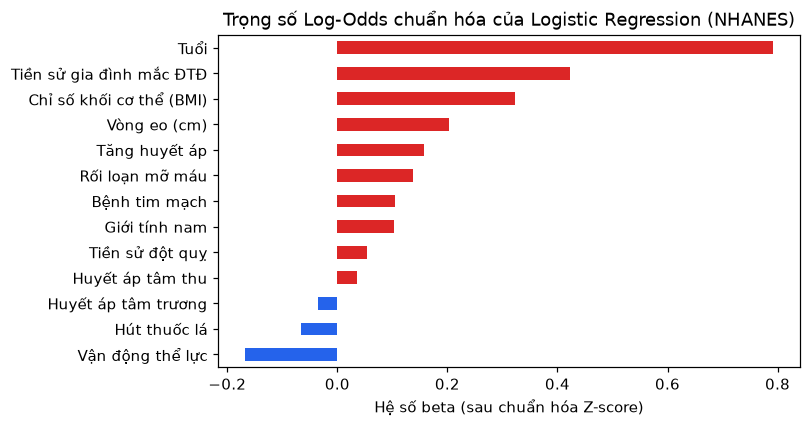

In [2]:
# Biểu đồ hệ số chuẩn hóa (Log-Odds) của các đặc trưng lâm sàng
coefs = pd.Series(clf.named_steps["logisticregression"].coef_[0], index=[spec.feature_vi[f] for f in spec.features]).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
coefs.plot(kind="barh", color=["#2563eb" if v < 0 else "#dc2626" for v in coefs], ax=ax)
ax.set_title("Trọng số Log-Odds chuẩn hóa của Logistic Regression (NHANES)")
ax.set_xlabel("Hệ số beta (sau chuẩn hóa Z-score)")
plt.tight_layout()